# Excitation Amplitude Scan — Analysis

Interactive analysis of `ExcitationScan` runs: **excitation amplitude (x) vs photon
collection probability (y)**.

This is a thin driver over `repository/analysis/analyze_excitation_scan.py` (the verified
analysis module); `%autoreload` picks up edits to that module without a kernel restart.

> **Run this in the working-BLAS `python` env, NOT `artiq7_claude`.** matplotlib's
> transforms hit the broken BLAS in `artiq7_claude` and hard-crash. numpy 2.2 / mpl 3.10
> is fine.

Per amplitude it computes `P = detections / attempts` over the gated measurements
(default gate = atom **loaded AND retained**), with 95% Wilson confidence intervals,
for SPCM1, SPCM2, and combined.

## 0. Setup

In [ ]:
%load_ext autoreload
%autoreload 2

import sys, os, glob, datetime
from pathlib import Path
import numpy as np
import h5py
import matplotlib.pyplot as plt

# Make the analysis module (and the repo's `analysis` package) importable.
ANALYSIS_DIR = Path(r"C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\repository\analysis")
REPO = ANALYSIS_DIR.parent                      # ...\repository
for p in (str(REPO), str(ANALYSIS_DIR)):
    if p not in sys.path:
        sys.path.insert(0, p)

from analyze_excitation_scan import (
    collection_probability, print_table, plot_scan, plot_timing, plot_timing_roi,
    write_csv, wilson_ci,
)

%matplotlib inline

RESULTS_DIR = REPO / "results"
print("Setup complete - functions from analyze_excitation_scan.py")
print(f"Results dir: {RESULTS_DIR}")

## 1. List Available ExcitationScan Runs

In [20]:
exc_files = sorted(glob.glob(str(RESULTS_DIR / "**" / "*-ExcitationScan.h5"), recursive=True))

if not exc_files:
    print(f"No ExcitationScan HDF5 files found under {RESULTS_DIR}")
else:
    print(f"{'RID':>9s}  {'Date':<12s}  {'HH':>3s}  {'N_meas':>7s}  {'N_amps':>7s}  Path")
    print("-" * 78)
    for fp in exc_files:
        fn = os.path.basename(fp)
        rid = fn.split("-")[0]
        mt = datetime.datetime.fromtimestamp(os.path.getmtime(fp))
        n_meas = n_amps = "?"
        try:
            with h5py.File(fp, "r", locking=False) as hf:
                if "datasets/exc_scan_amp" in hf:
                    amp = hf["datasets/exc_scan_amp"][()]
                    n_meas = str(len(amp))
                    n_amps = str(len(np.unique(np.round(amp, 6))))
        except Exception:
            pass
        rel = str(Path(fp).relative_to(RESULTS_DIR).parent)
        print(f"{rid:>9s}  {mt.strftime('%Y-%m-%d'):<12s}  {mt.strftime('%H'):>3s}  "
              f"{n_meas:>7s}  {n_amps:>7s}  {rel}")

      RID  Date           HH   N_meas   N_amps  Path
------------------------------------------------------------------------------
000000534  2026-06-09     18      333        9  2026-06-09\17
000000537  2026-06-09     22     3112        8  2026-06-09\18
000000540  2026-06-10     00      954        9  2026-06-09\23
000000543  2026-06-10     02     9000        9  2026-06-10\00


## 2. Select and Load a Run

Set `RID` to an integer run ID, or `None` for the latest. `GATE` controls which
measurements count toward the probability: `'both'` (atom loaded AND retained, default),
`'retained'`, `'loaded'`, or `'none'`.

In [21]:
########################################
RID  = None      # <-- int RID, or None for the latest run
GATE = "both"    # "both" | "retained" | "loaded" | "none"
########################################

exc_files = sorted(glob.glob(str(RESULTS_DIR / "**" / "*-ExcitationScan.h5"), recursive=True))
if not exc_files:
    raise FileNotFoundError(f"No ExcitationScan .h5 under {RESULTS_DIR}")

if RID is not None:
    matches = [f for f in exc_files if os.path.basename(f).startswith(f"{RID:09d}-")]
    if not matches:
        raise FileNotFoundError(f"No ExcitationScan run with RID {RID}")
    filepath = matches[-1]
else:
    filepath = exc_files[-1]
    print("(Using latest ExcitationScan run)")

filepath = str(filepath)
run_rid = int(os.path.basename(filepath).split("-")[0])
meta, rows = collection_probability(filepath, gate=GATE)

print(f"File         : {os.path.basename(filepath)}")
print(f"RID          : {run_rid}")
print(f"gate         : {GATE}")
print(f"measurements : {meta['n_gated']}/{meta['n_total']} kept")
print(f"amplitudes   : {len(rows)}")
if np.isfinite(meta['exc_best_amp']):
    print(f"exp best amp : {meta['exc_best_amp']:.3f}  (eff {meta['exc_best_efficiency']*100:.3f}%)")

(Using latest ExcitationScan run)
File         : 000000543-ExcitationScan.h5
RID          : 543
gate         : both
measurements : 8089/9000 kept
amplitudes   : 9
exp best amp : 0.160  (eff 0.774%)


## 3. Per-Amplitude Table

In [22]:
print_table(meta, rows)

File: 000000543-ExcitationScan.h5   gate=both   measurements kept: 8089/9000
  atoms loaded: 8912/9000   retained: 8093/9000   photons detected: SPCM1=77, SPCM2=69

     amp  n_meas   attempts         P1 % [95% CI]         P2 % [95% CI]       P_comb % [95% CI]
-----------------------------------------------------------------------------------------------
   0.100     915       2745   0.219 [0.100-0.476]   0.146 [0.057-0.374]     0.364 [0.198-0.669]
   0.110     892       2676   0.224 [0.103-0.488]   0.075 [0.020-0.272]     0.299 [0.152-0.589]
   0.120     881       2643   0.378 [0.206-0.695]   0.114 [0.039-0.333]     0.492 [0.288-0.840]
   0.130     905       2715   0.110 [0.038-0.324]   0.405 [0.226-0.724]     0.516 [0.307-0.864]
   0.140     901       2703   0.370 [0.201-0.680]   0.259 [0.126-0.534]     0.629 [0.393-1.005]
   0.150     891       2673   0.337 [0.177-0.639]   0.299 [0.152-0.590]     0.636 [0.397-1.016]
   0.160     904       2712   0.332 [0.175-0.630]   0.442 [0.253-0.

## 4. Plot: Excitation Amplitude vs Photon Collection Probability

The requested figure. `SHOW_SPCM=False` hides the individual SPCM1/SPCM2 curves and
shows only the combined probability. Error bars are 95% Wilson intervals; the peak
amplitude is marked.

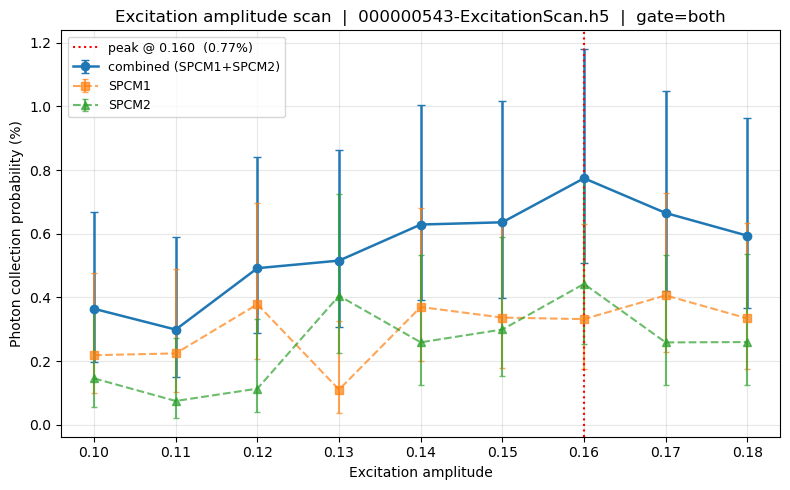

In [23]:
########################################
SHOW_SPCM = True     # also draw SPCM1 / SPCM2 individually
########################################

plot_scan(meta, rows, show_spcm=SHOW_SPCM)   # out=None -> inline

# Re-run with a different gate without reloading, e.g.:
#   meta2, rows2 = collection_probability(filepath, gate="retained")
#   plot_scan(meta2, rows2)

## 5. Photon Arrival-Time Profile (optional)

Histogram of photon arrival times (relative to excitation start) from the per-photon
`SPCM*_timestamps`. Set `TIMING_AMP` to a float to restrict to one amplitude, or `None`
for all amplitudes pooled.

Two figures: the **full range** (includes the nonsense ~-600000 ns out-of-gate
timestamps) and a **region-of-interest zoom** that drops them so the real emission peak
is visible. Set `ROI_LO` / `ROI_HI` (ns) to fix the window, or leave them `None` for an
automatic `[0, ~99.9th percentile]` window.

In [ ]:
########################################
TIMING_AMP = None    # None = all amplitudes, or e.g. meta['exc_best_amp']
ROI_LO     = None    # ns lower edge; None -> 0 (drops the negative junk)
ROI_HI     = None    # ns upper edge; None -> auto (~99.9th pct of real arrivals)
########################################

# Full range (includes the ~-600000 ns out-of-gate junk)
plot_timing(filepath, amp=TIMING_AMP)

# Region-of-interest zoom (excludes the junk, shows the real emission peak)
plot_timing_roi(filepath, amp=TIMING_AMP, roi_lo=ROI_LO, roi_hi=ROI_HI)

## 6. Export CSV (optional)

In [ ]:
# write_csv(meta, rows, f"excitation_scan_RID{run_rid}_{GATE}.csv")
print("Uncomment the line above to write the per-amplitude table as CSV.")

## 7. Dataset Browser

In [ ]:
with h5py.File(filepath, "r", locking=False) as hf:
    print(f"File: {os.path.basename(filepath)}   RID: {run_rid}\n")
    print("=== datasets/ ===")
    if "datasets" in hf:
        for k in sorted(hf["datasets"].keys()):
            ds = hf[f"datasets/{k}"]
            arr = ds[()]
            if hasattr(arr, "__len__") and len(arr) > 0:
                try:
                    print(f"  {k:26s} {str(ds.dtype):8s} shape={str(arr.shape):14s} "
                          f"[{float(np.min(arr)):.4g} .. {float(np.max(arr)):.4g}]")
                except Exception:
                    print(f"  {k:26s} {str(ds.dtype):8s} shape={str(arr.shape)}")
            else:
                val = arr.decode() if isinstance(arr, bytes) else arr
                print(f"  {k:26s} = {val}")